In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import carregar_noaa_por_tipo, filtrar_redes_superficie, carregar_bacias, pareados_por_raio, tabela_ajustes, plotar_mosaico

agua = carregar_noaa_por_tipo()["Água oceânica"]
conjuntos = {
    "Água oceânica (sem filtro)": agua,
    "Água oceânica (Redes de superfície)": filtrar_redes_superficie(agua),
    "Água oceânica (Manta net)": filtrar_redes_superficie(agua, ("Manta net",)),
}
bacias = carregar_bacias({"Água oceânica": agua})
print({k: len(v) for k, v in conjuntos.items()}, "| bacias:", len(bacias))

{'Água oceânica (sem filtro)': 14363, 'Água oceânica (Redes de superfície)': 13660, 'Água oceânica (Manta net)': 2981} | bacias: 179718


In [2]:
pareados = pareados_por_raio(bacias, conjuntos, raios=(5, 22))
print(tabela_ajustes(pareados, pop_mins=(0, 1000, 10000)).round(3).to_string(index=False))

                           Conjunto  R_km  Pop_min                X    N   beta    se  r2_pct  p_value    rho  r2_bins_pct  beta_bins_w
         Água oceânica (sem filtro)     5        0 total_population  754  0.346 0.032  13.246    0.000  0.418       96.382        0.344
         Água oceânica (sem filtro)     5        0         area_km2  754  0.575 0.092   4.970    0.000  0.315       42.263        0.553
         Água oceânica (sem filtro)     5     1000 total_population  421  0.601 0.084  10.920    0.000  0.384       91.232        0.621
         Água oceânica (sem filtro)     5     1000         area_km2  421  0.371 0.116   2.374    0.002  0.211       17.118        0.235
         Água oceânica (sem filtro)     5    10000 total_population  202  0.519 0.161   4.919    0.002  0.187       75.465        0.462
         Água oceânica (sem filtro)     5    10000         area_km2  202  0.082 0.145   0.161    0.571  0.023       50.314       -0.094
Água oceânica (Redes de superfície)     5       

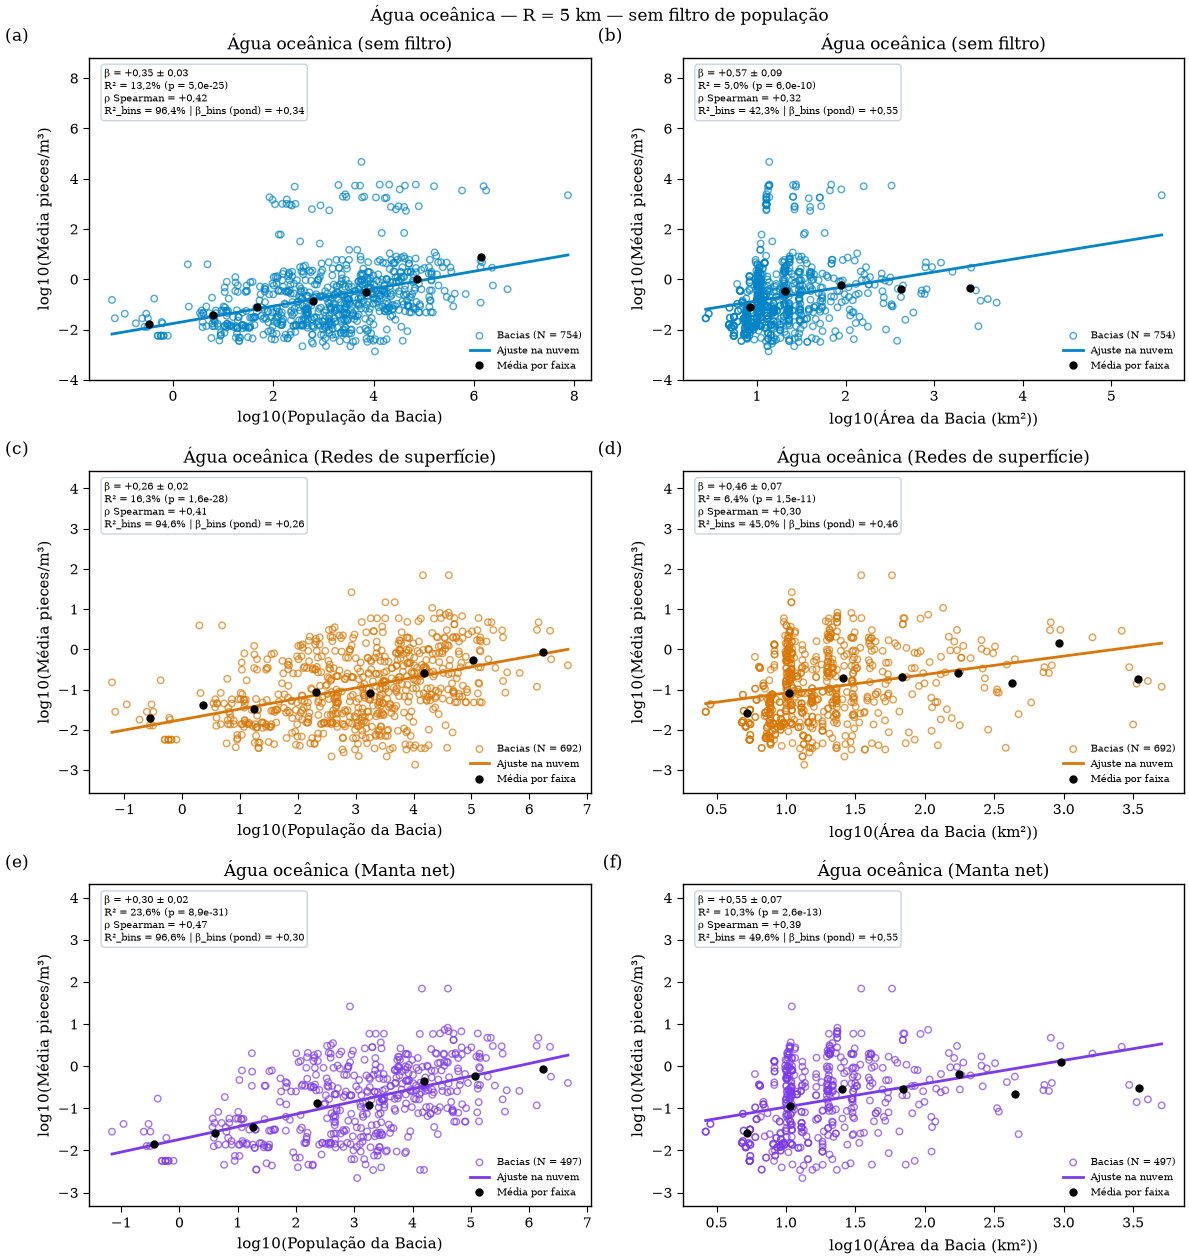

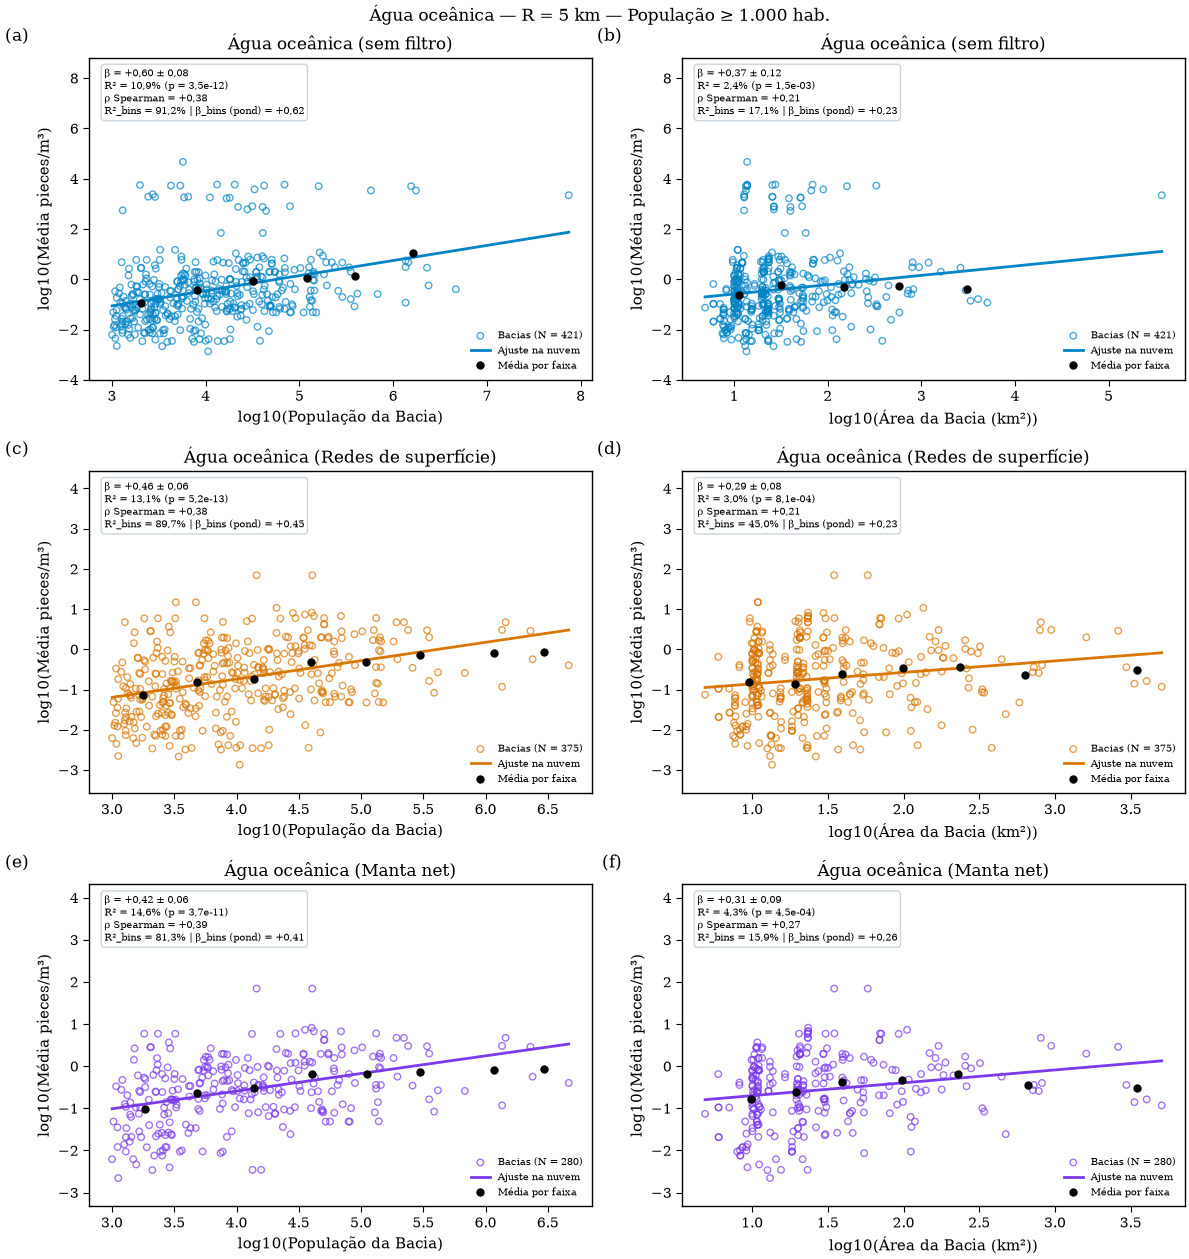

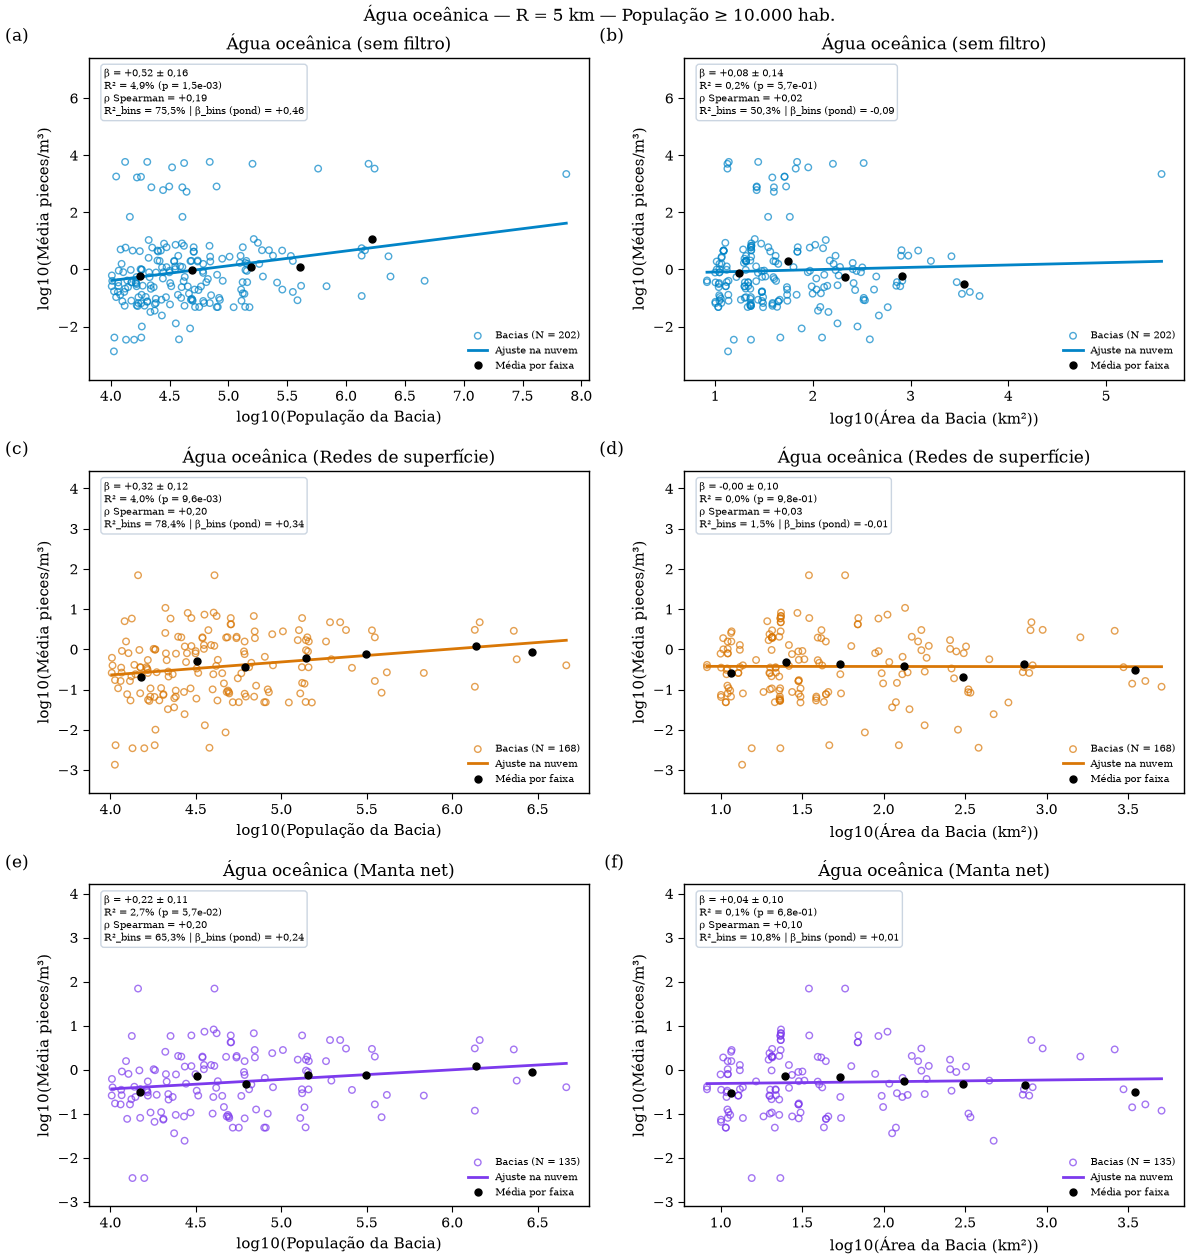

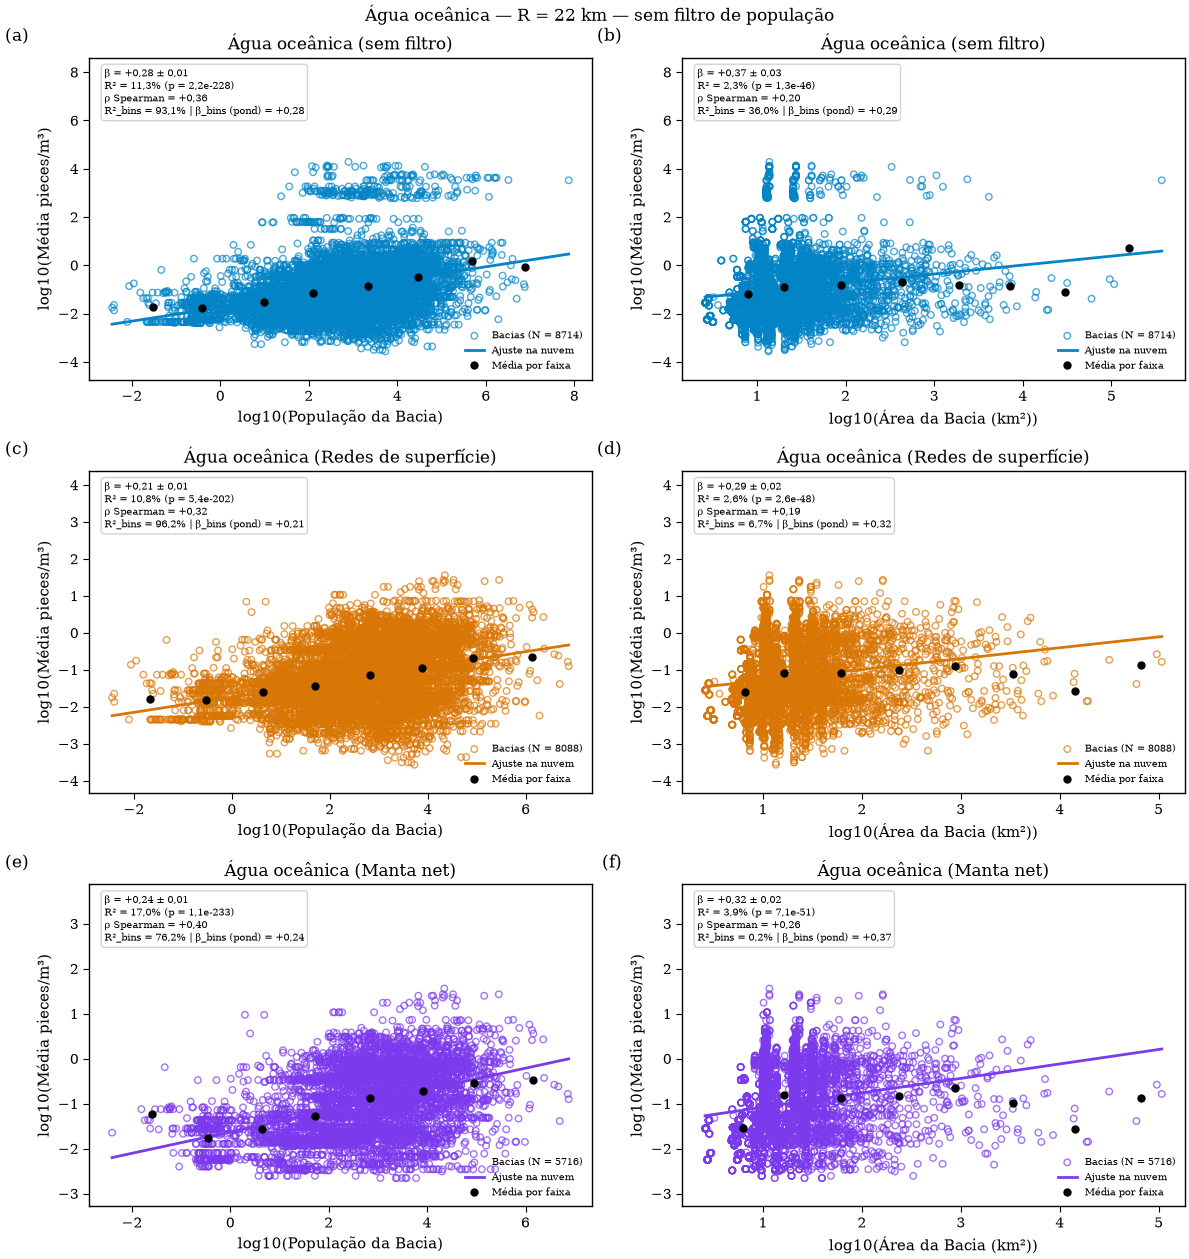

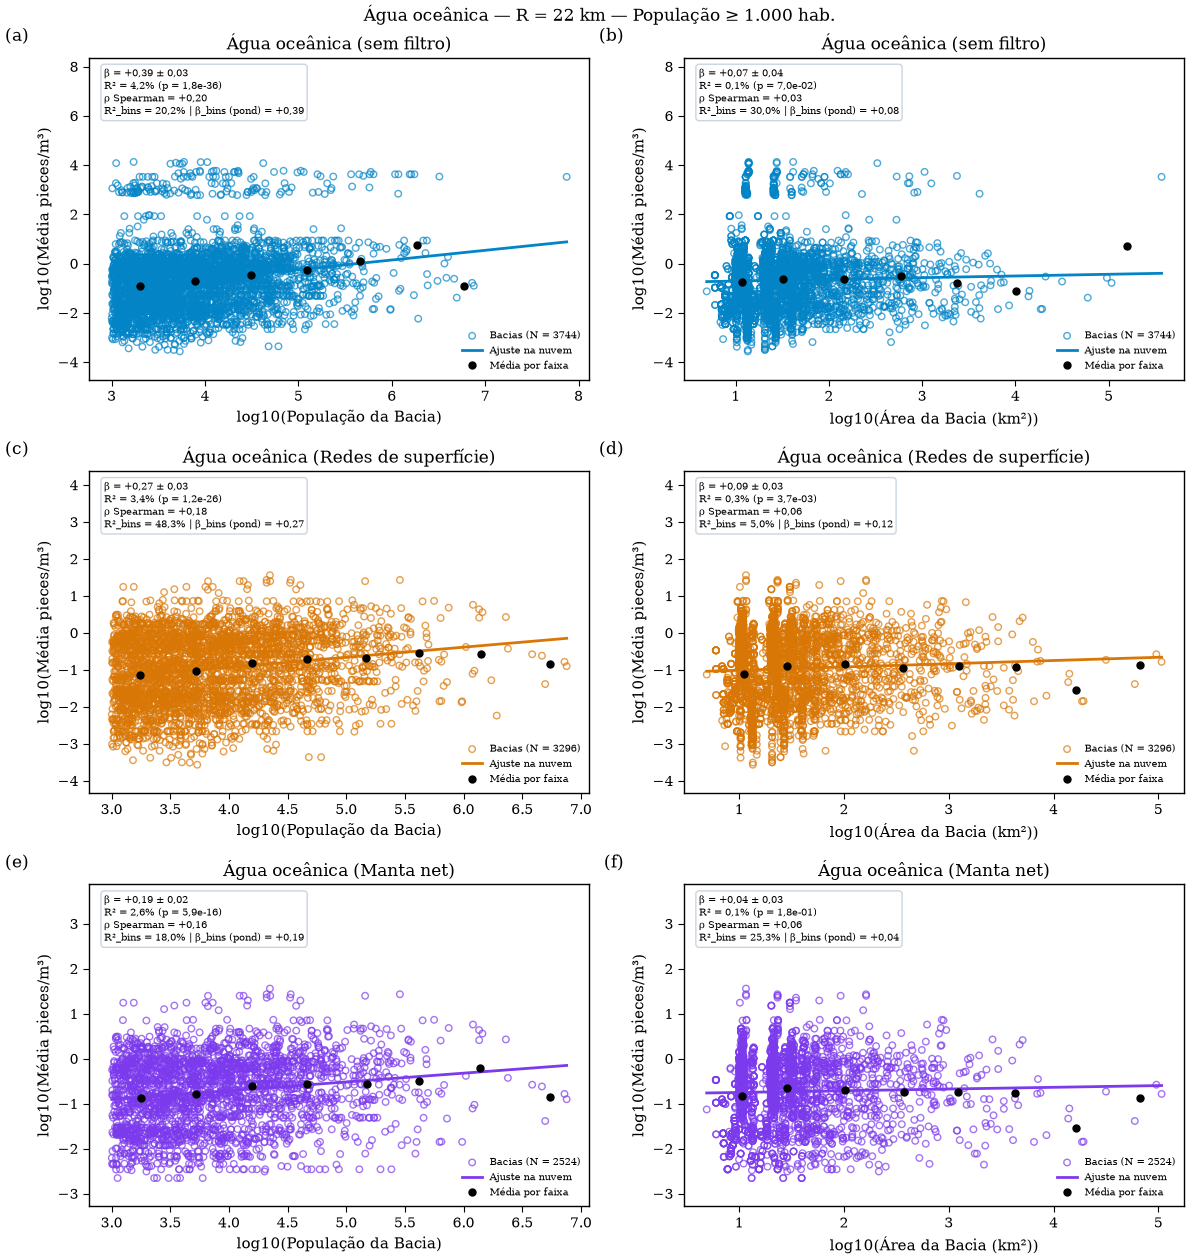

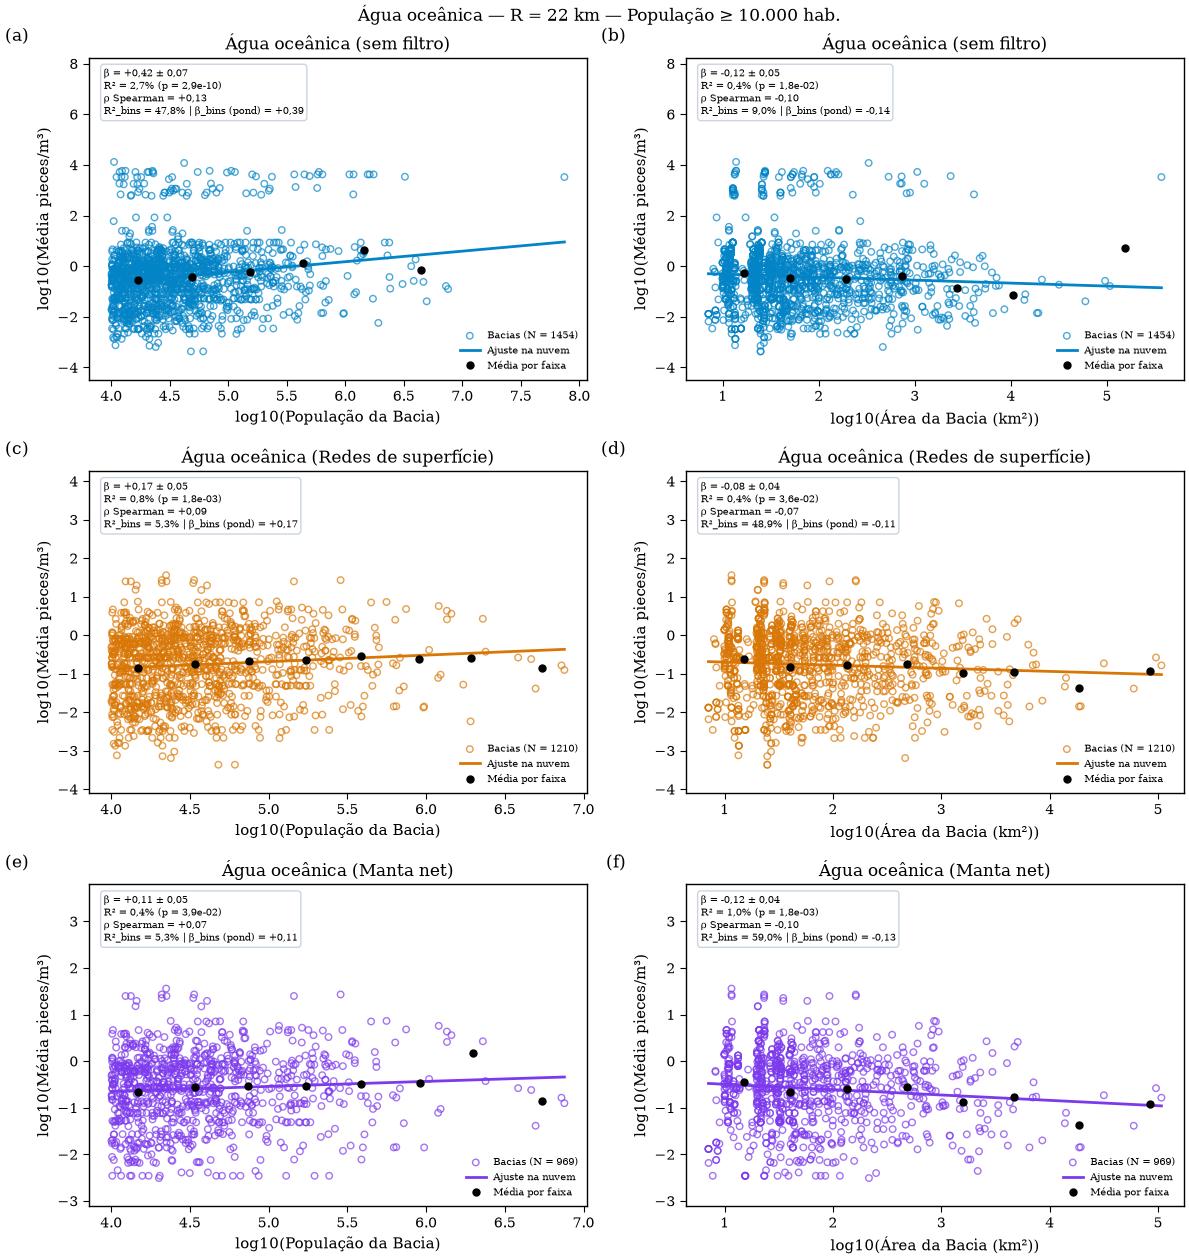

In [3]:
for r in (5, 22):
    for pop_min in (0, 1000, 10000):
        plotar_mosaico(pareados[r], f"Água oceânica — R = {r} km", pop_min, arquivo=f"comparacao_redes_superficie_R{r}_pop{pop_min}")